In [ ]:
from torchvision.datasets import MNIST
import torchvision.transforms as transformsv1

import torch.nn as nn
from torch.optim import Adam
import torch
import torch.utils.data
from torch.utils.data import DataLoader

from tqdm.auto import tqdm

import matplotlib.pyplot as plt

In [ ]:
transforms = transformsv1.Compose([
    transformsv1.ToTensor(),
])

mnist_dataset = MNIST("./MNIST", download=True, transform=transforms)

len(mnist_dataset)

60000

In [ ]:
mnist_dataset[0][0].shape

torch.Size([1, 28, 28])

In [ ]:
# Эта ячейка во время проверки автогрейдоером будет выделена в отдельный файл
# Не рекомендуется сюда добавлять лишние импорты или добавлять реализацию
# лишних классов или функций

# Строго запрещено менять названия классов в этой ячейке -- это сломает автотесты

# Вам нужно реализовать методы в классе VariationalAutoEncoder
# Остальные классы можете оставить как есть.

import torch
import torch.nn as nn

class ImageEncoder(nn.Module):
    def __init__(self, latent_dim=128):
        super().__init__()

        self.latent_dim = latent_dim

        self.sequential = nn.Sequential(*[
            nn.BatchNorm2d(1),
            nn.Conv2d(1, 64, kernel_size=3, padding=1),   # [ bs, 16, 28, 28 ]
            nn.ReLU(),
            nn.BatchNorm2d(64),
            nn.Conv2d(64, 128, kernel_size=3, padding=1), # [ bs, 64, 28, 28 ]
            nn.MaxPool2d(2),                              # [ bs, 128, 14, 14 ]
            nn.ReLU(),
            nn.BatchNorm2d(128),
            nn.Conv2d(128, self.latent_dim, kernel_size=1),     # [ bs, latent_dim, 14, 14 ]
            nn.Flatten(1),
        ])

    def forward(self, images_batch):
        return self.sequential(images_batch)


class ImageDecoder(nn.Module):
    def __init__(self, latent_dim=128):
        super().__init__()

        self.latent_dim = latent_dim

        self.sequential = nn.Sequential(*[
            nn.Unflatten(1, (self.latent_dim, 14, 14)),
            nn.BatchNorm2d(self.latent_dim),
            nn.Conv2d(128, 64, kernel_size=1), # [ bs, 64, 14, 14 ]
            nn.Upsample([28, 28]),             # [ bs, 128, 28, 28 ]
            nn.ReLU(),
            nn.BatchNorm2d(64),
            nn.Conv2d(64, 1, kernel_size=3, padding=1), # [ bs, 1, 28, 28 ]
            nn.ReLU(),
            nn.BatchNorm2d(1),
            nn.Conv2d(1, 1, kernel_size=3, padding=1), # [ bs, 1, 28, 28 ]
            nn.Sigmoid(),
        ])

    def forward(self, image_embedding):
        # image_embedding ~ [ bs, 128 ]
        assert len(image_embedding.shape) == 2
        assert image_embedding.shape[1] == self.latent_dim * 14 * 14, f"{image_embedding.shape[1]} == {self.latent_dim}"
        return self.sequential(image_embedding)

class VariationalAutoEncoder(nn.Module):
    def __init__(self, latent_dim=128):
        super().__init__()

        self.latent_dim = latent_dim

        self.encoder = ImageEncoder(latent_dim=latent_dim*2) # encoder generates mean and variances
        self.decoder = ImageDecoder(latent_dim=128)

    def encode(self, images_batch):
        """
        Отвечает за получение характеристик для скрытого состояния

        На вход принимает:
        * images_batch ~ [bs, 1, 28, 28]

        Возвращает:
        * Характеристики для скрытогоо состояния ~ [bs, latent_dim * 2]
        """

        return # TODO

    def decode(self, images_embeddings_mean, images_embeddings_variance):
        """
        В этом методе нужно реализовать reparametrization trick и восстановить
        изображение через decoder

        На вход принимает:
        * images_embeddings_mean - вектор скрытых средних ~ [bs, self.latent_dim]
        * images_embeddings_variance - вектор скрытых логарифмов дисперсий ~ [bs, self.latent_dim]

        Возвращает:
        * Восстановленное изображение ~ [bs, 1, 28, 28]
        """

        # reparametrization trick is here!
        images_embeddings = ... # TODO

        return # TODO

    def forward(self, images_batch):
        """
        На вход получает:
        * images_batch [bs, 1, 28, 28] - тензор входного изображения

        Возвращает тупл из трех элементов:
        1) Восстановленное изображение (прогнанное через encoder и восстановленое через decoder) ~ [bs, 1, 28, 28]
        2) Вектор скрытых средних ~ [bs, self.latent_dim]
        3) Вектор скрытых логарифмов дисперсий ~ [bs, self.latent_dim]

        2, 3 - нужны чтобы вычислить компоненту регуляризации в лоссе VAE

        Для реализации этго метода вам могут потребоваться:
        torch.chunk - для разделения эмбэддинга, полученного от енкодера на две части: вектор средних и логарифм дисперсии
        """
        # TODO encode

        # TODO chunk

        return # TODO decode



In [ ]:
mnist_dataset[0][0].shape

torch.Size([1, 28, 28])

In [ ]:
def test_smoke_variational_autoencoder():
    input_tensor = torch.rand( [ 5, 1, 28, 28 ] )
    variational_autoencoder_output = VariationalAutoEncoder().forward( input_tensor )
    assert len(variational_autoencoder_output) == 3, "VariationalAutoEncoder is expected to be a tuple of: reconstructed_image, images_embeddings_mean, images_embeddings_log_variance"
    assert input_tensor.shape == variational_autoencoder_output[0].shape, "Reconstructed image shape matches input image"

    return

test_smoke_variational_autoencoder()

In [ ]:
def train(model, dataset, loss_function, num_epochs=10, device='cuda', learning_rate=3e-4):

    # Путь бравых -- это реализовать трейн луп самостоятельно
    # Путь хитрых -- взять реализацию из семинара по AE

    return

In [ ]:
# Эта ячейка во время проверки автогрейдоером будет выделена в отдельный файл
# Не рекомендуется сюда добавлять лишние импорты или добавлять реализацию
# лишних классов или функций

# Строго запрещено менять название метода в этой ячейке -- это сломает автотесты

# Задача:
# Реализуйте ф-ю для вычисления лосса VAE.
# В качестве лосса для реконструкции используйте L1 loss
# Не забудьте про регуляризационную состоавляющую, которая отвечает
# за распределение средних и дисперсий VAE.
#
# В качестве регуляризационной составляющей нужно реализовать формулу
# KL расстояния между двумя гауссианами -- (mu=0, sigma=1) и вторая из тех параметров, которые мы получили из енкодера
# Формулу для KL расстояния мужду гауссианами можно нагуглить :)
#
# Обратите внимание, что последний элемент в model_out -- это именно **логарифм дисперсии**, не СКО!

import torch
from torch.nn.functional import l1_loss

def vae_loss(model_out, target_image, regularization_lambda=0.002):
    reconstructed_image, images_embeddings_mean, images_embeddings_log_variance = model_out

    reconstruction_loss_value = # TODO

    # kl div of gaussians
    regularization_loss = # TODO

    return reconstruction_loss_value + regularization_lambda * regularization_loss


In [ ]:
def test_regularization_term():
    # В этом тесте проверяется корректность вычисления регуляризационной составляющей лосса

    test_target_image = torch.ones(10, 10)
    test_model_out = (test_target_image, torch.ones(10), torch.ones(10))

    expected_loss = torch.tensor(0.8591)
    calculated_loss = vae_loss(test_model_out, test_target_image, regularization_lambda=1.0)
    print("test_regularization_term: calculated_loss", calculated_loss)
    print("test_regularization_term: expected_loss", expected_loss)
    assert torch.allclose(calculated_loss, expected_loss, atol=1e-4), f"expected_loss={expected_loss} calculated_loss={calculated_loss}"

def test_reconstruct_term():
    # В этом тесте проверяется корректность вычисления составляющей лосса, отвечающей за реконструкцию

    test_target_image = torch.zeros(10, 10)
    test_model_out = (torch.ones(10, 10), torch.ones(10), torch.ones(10))

    expected_loss = torch.tensor(1.0)
    calculated_loss = vae_loss(test_model_out, test_target_image, regularization_lambda=0.0)
    print("test_reconstruct_term: calculated_loss", calculated_loss)
    print("test_reconstruct_term: expected_loss", expected_loss)
    assert torch.allclose(calculated_loss, expected_loss, atol=1e-4), f"expected_loss={expected_loss} calculated_loss={calculated_loss}"


test_regularization_term()
test_reconstruct_term()

test_regularization_term: calculated_loss tensor(0.8591)
test_regularization_term: expected_loss tensor(0.8591)
test_reconstruct_term: calculated_loss tensor(1.)
test_reconstruct_term: expected_loss tensor(1.)


In [ ]:
variational_autoencoder = VariationalAutoEncoder()

device = 'cuda' if torch.cuda.is_available() else 'cpu'

generator = torch.Generator().manual_seed(42)

train(variational_autoencoder, mnist_dataset, vae_loss, device=device, num_epochs=10, learning_rate=3e-4)

Epoch:   0%|          | 0/10 [00:00<?, ?it/s]

In [ ]:
# В этой ячейке вам предстоит реализовать метод для исследования скрытого пространства
# VAE с помощью линейной интерполяции между двумя скрытыми состояниями.
# Похожий метод реализован в семинаре для AE. Догадайтесь, как его можно
# было бы модифицировать, чтобы применить его к VAE?

# Пример работы метода есть в самом конце ноутбука

# Автотестов к этому методу нет, но я рекомендую добить эту ф-ю в рамках домашки -- это ведь интересно)

@torch.no_grad
def linear_latent_space_interpolation_vae(model, image_from, image_to, device='cpu', num_interpolation_steps=10):
    model.eval()

    image_from = image_from.unsqueeze(0).to(device)
    image_to = image_to.unsqueeze(0).to(device)
    model = model.to(device)

    latent_space_from = model.encode(image_from)
    latent_space_to = model.encode(image_to)

    # TODO chunk

    latent_space_steps = torch.linspace(0, 1, num_interpolation_steps)

    # TODO calc diff

    restored_images = []
    for latent_step_portion in latent_space_steps:
        # TODO

        latent_interpolation_mean = # TODO
        latent_interpolation_log_variance = # TODO

        restored_image = model.decode(latent_interpolation_mean, latent_interpolation_log_variance).detach().clip(0, 1).cpu().numpy()[0]
        restored_images.append(restored_image)

    return restored_images

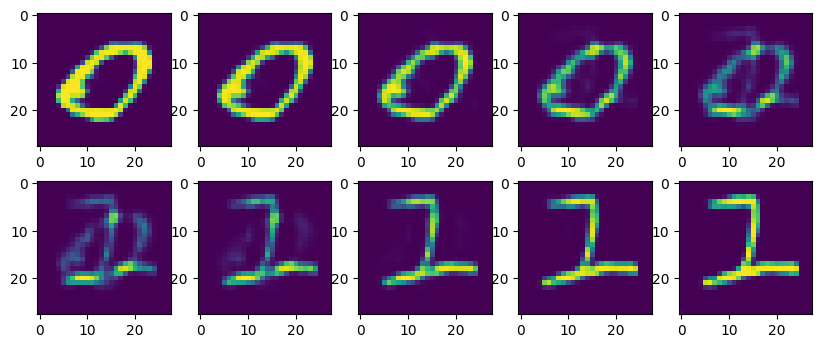

In [ ]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

variational_autoencoder_interpolated = linear_latent_space_interpolation_vae(
    variational_autoencoder, mnist_dataset[1][0], mnist_dataset[2][0],
    device=device,
    num_interpolation_steps=10
)

_, axs = plt.subplots(2, 5, figsize=(10, 4))
axs = axs.flatten()
for img, ax in zip(variational_autoencoder_interpolated, axs):
    ax.imshow(img.T)
plt.show()